# Import Libraries

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

# Create Dataset

In [2]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age': [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0]
}

df = pd.DataFrame(data)

print(df)

   Height  Weight  Age  Gender
0     170      65   30       1
1     165      59   25       0
2     180      75   35       1
3     175      68   28       1
4     160      55   22       0
5     172      70   32       1
6     168      62   27       0
7     177      74   33       1
8     162      58   24       0
9     158      54   21       0


# Check Dataset Information

In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nDataset Description:")
print(df.describe())

Dataset Shape:
(10, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Height  10 non-null     int64
 1   Weight  10 non-null     int64
 2   Age     10 non-null     int64
 3   Gender  10 non-null     int64
dtypes: int64(4)
memory usage: 452.0 bytes
None

Dataset Description:
           Height    Weight        Age     Gender
count   10.000000  10.00000  10.000000  10.000000
mean   168.700000  64.00000  27.700000   0.500000
std      7.439385   7.60117   4.762119   0.527046
min    158.000000  54.00000  21.000000   0.000000
25%    162.750000  58.25000  24.250000   0.000000
50%    169.000000  63.50000  27.500000   0.500000
75%    174.250000  69.50000  31.500000   1.000000
max    180.000000  75.00000  35.000000   1.000000


# Separate Features and Target

In [4]:
X = df.drop('Gender', axis=1)
y = df['Gender']

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

Features (X):
   Height  Weight  Age
0     170      65   30
1     165      59   25
2     180      75   35
3     175      68   28
4     160      55   22
5     172      70   32
6     168      62   27
7     177      74   33
8     162      58   24
9     158      54   21

Target (y):
0    1
1    0
2    1
3    1
4    0
5    1
6    0
7    1
8    0
9    0
Name: Gender, dtype: int64


# Standardize the Features

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Data:")
print(X_scaled)

Standardized Data:
[[ 0.18419807  0.13867505  0.50910379]
 [-0.52425605 -0.69337525 -0.59764358]
 [ 1.60110632  1.52542554  1.61585117]
 [ 0.8926522   0.5547002   0.06640484]
 [-1.23271018 -1.24807544 -1.26169201]
 [ 0.46757972  0.83205029  0.95180275]
 [-0.09918358 -0.2773501  -0.15494463]
 [ 1.17603385  1.38675049  1.17315222]
 [-0.94932853 -0.83205029 -0.81899306]
 [-1.51609183 -1.38675049 -1.48304149]]


# Apply PCA

In [6]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA Data:")
print(X_pca)

PCA Data:
[[ 0.47934953  0.24005867]
 [-1.04854122 -0.0462082 ]
 [ 2.73763841  0.01704297]
 [ 0.87462551 -0.58608547]
 [-2.16068418 -0.02240454]
 [ 1.30013241  0.33690873]
 [-0.30743041 -0.03219976]
 [ 2.15777883 -0.01054754]
 [-1.50115252  0.08802759]
 [-2.53171635  0.01540757]]


# Explained Variance

In [7]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")

print(sum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[0.97871061 0.01755646]

Total Variance Explained:
0.9962670732254938


# Display PCA Components

In [8]:
print("Principal Components:")

print(pca.components_)

Principal Components:
[[ 0.57575457  0.58139955  0.57487498]
 [-0.68052174 -0.04897084  0.73108961]]


# Create PCA DataFrame

In [9]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['Principal Component 1', 'Principal Component 2']
)

pca_df['Gender'] = y.values

print(pca_df)

   Principal Component 1  Principal Component 2  Gender
0               0.479350               0.240059       1
1              -1.048541              -0.046208       0
2               2.737638               0.017043       1
3               0.874626              -0.586085       1
4              -2.160684              -0.022405       0
5               1.300132               0.336909       1
6              -0.307430              -0.032200       0
7               2.157779              -0.010548       1
8              -1.501153               0.088028       0
9              -2.531716               0.015408       0


# Split Data into Training and Testing

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.3,
    random_state=42
)

print("Training Data:")
print(X_train)

print("\nTesting Data:")
print(X_test)

Training Data:
[[ 0.47934953  0.24005867]
 [ 2.15777883 -0.01054754]
 [ 2.73763841  0.01704297]
 [-2.53171635  0.01540757]
 [-2.16068418 -0.02240454]
 [ 0.87462551 -0.58608547]
 [-0.30743041 -0.03219976]]

Testing Data:
[[-1.50115252  0.08802759]
 [-1.04854122 -0.0462082 ]
 [ 1.30013241  0.33690873]]


# Train Logistic Regression Model

In [11]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


# Make Predictions

In [12]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)

Predicted Values:
[0 0 1]

Actual Values:
[0 0 1]


# Calculate Accuracy

In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 1.0
Accuracy Percentage: 100.0 %


# Classification Report

In [14]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Female', 'Male'],
    zero_division=0
))

              precision    recall  f1-score   support

      Female       1.00      1.00      1.00         2
        Male       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



# Confusion Matrix

In [15]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2 0]
 [0 1]]


# Visualize Confusion Matrix

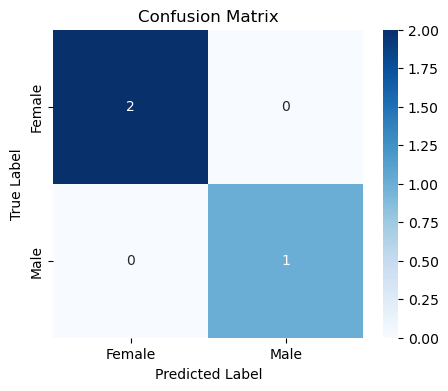

In [16]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Female', 'Male'],
    yticklabels=['Female', 'Male']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

plt.show()

# Visualization Before PCA

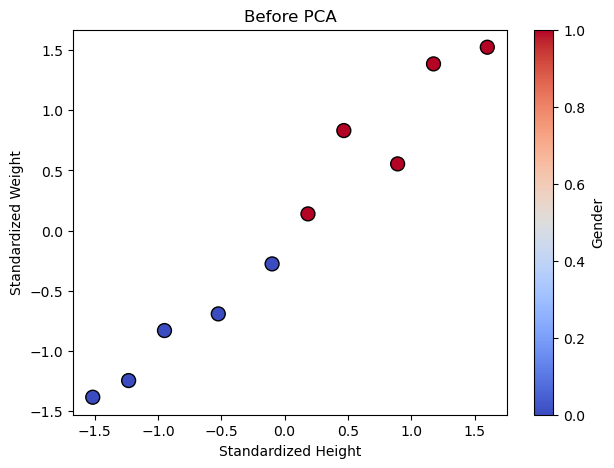

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap='coolwarm',
    edgecolor='k',
    s=100
)

plt.xlabel('Standardized Height')
plt.ylabel('Standardized Weight')
plt.title('Before PCA')

plt.colorbar(label='Gender')

plt.show()

# Visualization After PCA

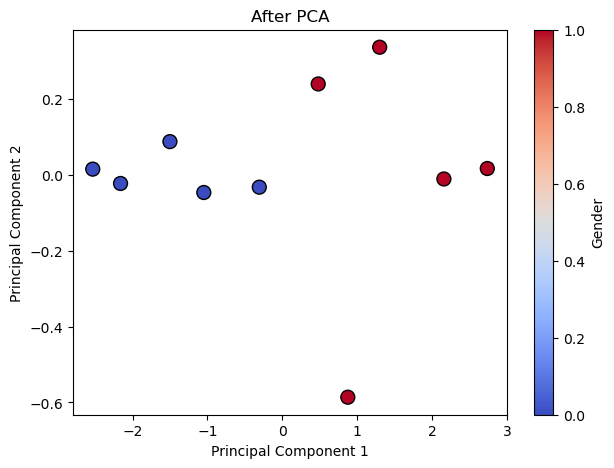

In [18]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap='coolwarm',
    edgecolor='k',
    s=100
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('After PCA')

plt.colorbar(label='Gender')

plt.show()

# Explained Variance Graph

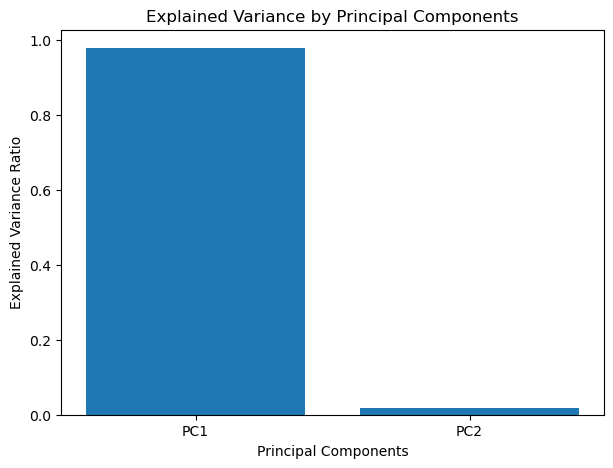

In [19]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['PC1', 'PC2'],
    pca.explained_variance_ratio_
)

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')

plt.title('Explained Variance by Principal Components')

plt.show()

# Scree Plot

In [20]:
pca_all = PCA()

X_pca_all = pca_all.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca_all.explained_variance_ratio_)

Explained Variance Ratio:
[0.97871061 0.01755646 0.00373293]


# Draw Scree Plot

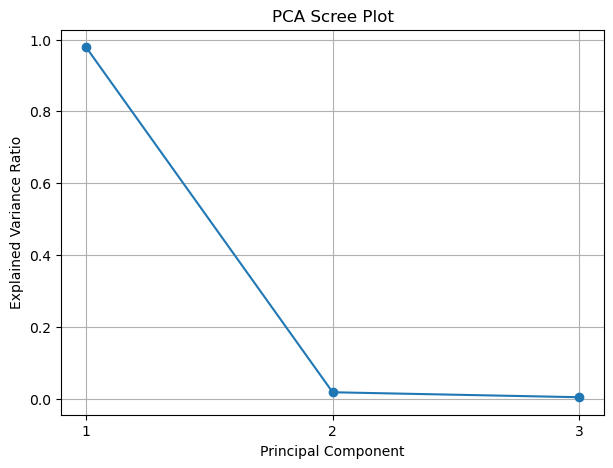

In [21]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(pca_all.explained_variance_ratio_) + 1),
    pca_all.explained_variance_ratio_,
    marker='o'
)

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')

plt.title('PCA Scree Plot')

plt.xticks(
    range(1, len(pca_all.explained_variance_ratio_) + 1)
)

plt.grid()

plt.show()

# Cumulative Explained Variance

In [22]:
cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

print("Cumulative Explained Variance:")
print(cumulative_variance)

Cumulative Explained Variance:
[0.97871061 0.99626707 1.        ]


# Cumulative Variance Graph

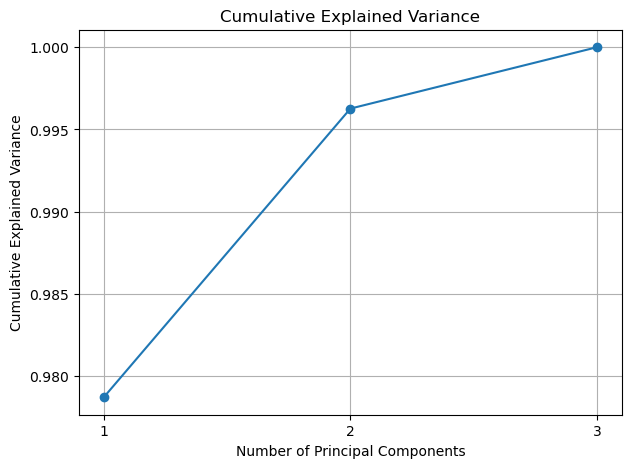

In [23]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')

plt.title('Cumulative Explained Variance')

plt.xticks(
    range(1, len(cumulative_variance) + 1)
)

plt.grid()

plt.show()